<a href="https://colab.research.google.com/github/danilejt/DataAnalytics-2026/blob/main/Exercise_XP_Week_3_Day_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [13]:
#importing the kaggle legacy api
from google.colab import files
files.upload()


Saving kaggle.json to kaggle (1).json


{'kaggle (1).json': b'{"username":"jlemdaniella","key":"cc9e22f516ac0dc1b059de4d962201ff"}'}

In [14]:
# Create the directory and copy the token
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json


In [15]:
# Download the Titanic competition dataset
!kaggle competitions download -c titanic

titanic.zip: Skipping, found more recently modified local copy (use --force to force download)


In [16]:
# unzip file לפי ai
# import zipfile
# import pandas as pd

# # Unzip the downloaded files
# with zipfile.ZipFile('titanic.zip', 'r') as zip_ref:
#     zip_ref.extractall('titanic_data')

# # Load the training data
# train_df = pd.read_csv('titanic_data/train.csv')
# print(train_df.head())

In [17]:
!unzip titanic.zip

Archive:  titanic.zip
replace gender_submission.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
  inflating: gender_submission.csv   
replace test.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
  inflating: test.csv                
replace train.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
  inflating: train.csv               


In [18]:
import pandas as pd

# Load the Titanic dataset
titanic_data = pd.read_csv('train.csv')

# Explore the dataset
#print(titanic_data.head())
print(titanic_data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
None


In [21]:
# Load additional dataset (hypothetical example)
#passenger_demographics = pd.read_csv(r"titanic_demographics.csv")



In [33]:
# Perform data integration (merge datasets on a common key)
#integrated_data = pd.merge(titanic_data, passenger_demographics, on='PassengerId', how='left')

# Explore the integrated dataset
#print(integrated_data.head())
#print(integrated_data.info())

🌟 Exercise 1: Duplicate Detection and Removal
Instructions
Objective: Identify and remove duplicate entries in the Titanic dataset.

Load the Titanic dataset.
Identify if there are any duplicate rows based on all columns.
Remove any duplicate rows found in the dataset.
Verify the removal of duplicates by checking the number of rows before and after the duplicate removal.
Hint: Use the duplicated() and drop_duplicates() functions in Pandas.

In [34]:
# Remove duplicate rows
titanic_data = titanic_data.drop_duplicates()

# Verify duplicates are removed
print(titanic_data.duplicated().sum())
print(titanic_data.info())

0
<class 'pandas.core.frame.DataFrame'>
Index: 775 entries, 0 to 890
Data columns (total 30 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   PassengerId     775 non-null    int64  
 1   Survived        775 non-null    int64  
 2   Pclass          775 non-null    int64  
 3   Name            775 non-null    object 
 4   Sex             775 non-null    object 
 5   Age             613 non-null    float64
 6   SibSp           775 non-null    int64  
 7   Parch           775 non-null    int64  
 8   Ticket          775 non-null    object 
 9   Fare            775 non-null    float64
 10  Cabin           114 non-null    object 
 11  Embarked        775 non-null    object 
 12  Family_Size     775 non-null    int64  
 13  Is_Alone        775 non-null    int64  
 14  Title           775 non-null    object 
 15  Title_Encoded   775 non-null    int64  
 16  Title_Col       775 non-null    int64  
 17  Title_Don       775 non-null    int64 

In [35]:
titanic_data = titanic_data.drop(['Cabin'], axis=1, errors='ignore')
print(titanic_data.info())


<class 'pandas.core.frame.DataFrame'>
Index: 775 entries, 0 to 890
Data columns (total 29 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   PassengerId     775 non-null    int64  
 1   Survived        775 non-null    int64  
 2   Pclass          775 non-null    int64  
 3   Name            775 non-null    object 
 4   Sex             775 non-null    object 
 5   Age             613 non-null    float64
 6   SibSp           775 non-null    int64  
 7   Parch           775 non-null    int64  
 8   Ticket          775 non-null    object 
 9   Fare            775 non-null    float64
 10  Embarked        775 non-null    object 
 11  Family_Size     775 non-null    int64  
 12  Is_Alone        775 non-null    int64  
 13  Title           775 non-null    object 
 14  Title_Encoded   775 non-null    int64  
 15  Title_Col       775 non-null    int64  
 16  Title_Don       775 non-null    int64  
 17  Title_Dr        775 non-null    int64  


 Exercise 2: Handling Missing Values
Instructions
Identify columns in the Titanic dataset with missing values.
Explore different strategies for handling missing data, such as removal, imputation, and filling with a constant value.
Apply each strategy to different columns based on the nature of the data.
Hint: Review methods like dropna(), fillna(), and SimpleImputer from scikit-learn.



In [36]:
import pandas as pd

# Check for missing values in a DataFrame
missing_data = titanic_data.isnull()
#print(missing_data.info())

# Count missing values in each column
missing_counts = titanic_data.isnull().sum()
print(missing_counts)

PassengerId         0
Survived            0
Pclass              0
Name                0
Sex                 0
Age               162
SibSp               0
Parch               0
Ticket              0
Fare                0
Embarked            0
Family_Size         0
Is_Alone            0
Title               0
Title_Encoded       0
Title_Col           0
Title_Don           0
Title_Dr            0
Title_Jonkheer      0
Title_Lady          0
Title_Major         0
Title_Master        0
Title_Miss          0
Title_Mlle          0
Title_Mr            0
Title_Mrs           0
Title_Ms            0
Title_Rev           0
Title_Sir           0
dtype: int64


In [37]:
# Remove rows with missing values
titanic_data_cleaned = titanic_data.dropna()

# Remove columns with missing values
titanic_data_cleaned = titanic_data.dropna(axis=1)

In [38]:
# Fill missing values with a specific value (e.g., 0)
titanic_data_filled = titanic_data.fillna(0)

# Fill missing values with the mean of the column
#titanic_data_filled = titanic_data.fillna(titanic_data.mean())

print(titanic_data.head())

   PassengerId  Survived  Pclass  \
0            1         0       3   
2            3         1       3   
3            4         1       1   
4            5         0       3   
5            6         0       3   

                                           Name     Sex   Age  SibSp  Parch  \
0                       Braund, Mr. Owen Harris    male  22.0      1      0   
2                        Heikkinen, Miss. Laina  female  26.0      0      0   
3  Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1      0   
4                      Allen, Mr. William Henry    male  35.0      0      0   
5                              Moran, Mr. James    male   NaN      0      0   

             Ticket     Fare  ... Title_Lady  Title_Major  Title_Master  \
0         A/5 21171   7.2500  ...          0            0             0   
2  STON/O2. 3101282   7.9250  ...          0            0             0   
3            113803  53.1000  ...          0            0             0   
4       

In [39]:
# from sklearn.impute import KNNImputer

# imputer = KNNImputer(n_neighbors=2)
# df_imputed = imputer.fit_transform(titanic_data)

# # 1. Identify numerical columns
# numeric_cols = titanic_data.select_dtypes(include=["number"]).columns

# # 2. Initialize and apply the imputer only to those columns
# imputer = KNNImputer(n_neighbors=2)
# titanic_data[numeric_cols] = imputer.fit_transform(titanic_data[numeric_cols])

In [40]:
# Identify and handle outliers in 'Fare' column
Q1 = titanic_data['Fare'].quantile(0.25)
Q3 = titanic_data['Fare'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
titanic_data = titanic_data[(titanic_data['Fare'] >= lower_bound) & (titanic_data['Fare'] <= upper_bound)]

1. Calculate the first quartile (Q1) and the third quartile (Q3) for the Age column in the Titanic dataset.

2. Compute the interquartile range (IQR) for the Age column.

3. Define the lower bound and upper bound for potential outliers based on the IQR.

4. Identify and count the number of outliers in the Age column if there is.

In [41]:
# Identify and handle outliers in 'Age' column
Q1 = titanic_data['Age'].quantile(0.25)
Q3 = titanic_data['Age'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = titanic_data[(titanic_data["Age"] < lower_bound) | (titanic_data["Age"] > upper_bound)]

# 5. Count the outliers
outlier_count = len(outliers)

print(f"Age boundaries: {lower_bound} to {upper_bound}")
print(f"Number of outliers in Age: {outlier_count}")

Age boundaries: -4.0 to 60.0
Number of outliers in Age: 17




🌟 Exercise 3: Feature Engineering
Instructions
- Create new features, such as Family Size from SibSp and Parch, and
-  Title extracted from the Name column.
- Convert categorical variables into numerical form using techniques like one-hot encoding or
- Convert categorical variables into numerical form using techniques like label encoding.
- You will encode new categorical features (like Title) here, but do not scale numerical features yet — that will come after outlier handling.
Hint: Utilize Pandas for data manipulation and scikit-learn’s preprocessing module for encoding.


In [42]:
titanic_data["Family_Size"] = titanic_data['SibSp'] + titanic_data['Parch'] + 1
titanic_data["Is_Alone"] = (titanic_data['Family_Size'] == 1).astype(int)


In [43]:
titanic_data['Title'] = titanic_data['Name'].str.split(', ', expand=True)[1].str.split('.', expand=True)[0]

# View the extracted titles
print(titanic_data['Title'].value_counts())

Title
Mr          464
Miss        139
Mrs          91
Master       36
Rev           6
Dr            5
Major         2
Col           2
Don           1
Ms            1
Lady          1
Mlle          1
Jonkheer      1
Name: count, dtype: int64


In [44]:
# 1. Label Encoding
#mapping each title to a number
title_mapping = {
    "Mr": 1,
    "Miss": 2, "Mlle": 2, "Ms": 2,  # Grouping variations of Miss
    "Mrs": 3, "Mme": 3,              # Grouping variations of Mrs
    "Master": 4,
    # Rare titles grouped together as 5
    "Dr": 5, "Rev": 5, "Col": 5, "Major": 5, "Mlle": 2, "Countess": 5,
    "Jonkheer": 5, "Don": 5, "Dona": 5, "Lady": 5, "Sir": 5, "Capt": 5
}

# 2. Apply the mapping to the Title column
# .map() replaces the text with the numbers; .fillna(5) handles any unmapped rare titles
titanic_data['Title_Encoded'] = titanic_data['Title'].map(title_mapping).fillna(5)

# View the results
print(titanic_data[['Title', 'Title_Encoded']].head())


  Title  Title_Encoded
0    Mr              1
2  Miss              2
3   Mrs              3
4    Mr              1
5    Mr              1


In [45]:
#one-hot encoding - still having trouble with this!!
# Create binary columns for each title
title_dummies = pd.get_dummies(titanic_data['Title'], prefix='Title', dtype=int)

# Join the new columns back to your original dataframe
titanic_data = pd.concat([titanic_data, title_dummies], axis=1)

# View the new columns (e.g., Title_Mr, Title_Miss, Title_Mrs)
print(titanic_data.head())

   PassengerId  Survived  Pclass  \
0            1         0       3   
2            3         1       3   
3            4         1       1   
4            5         0       3   
5            6         0       3   

                                           Name     Sex   Age  SibSp  Parch  \
0                       Braund, Mr. Owen Harris    male  22.0      1      0   
2                        Heikkinen, Miss. Laina  female  26.0      0      0   
3  Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1      0   
4                      Allen, Mr. William Henry    male  35.0      0      0   
5                              Moran, Mr. James    male   NaN      0      0   

             Ticket     Fare  ... Title_Jonkheer  Title_Lady  Title_Major  \
0         A/5 21171   7.2500  ...              0           0            0   
2  STON/O2. 3101282   7.9250  ...              0           0            0   
3            113803  53.1000  ...              0           0            0   





🌟 Exercise 4: Outlier Detection and Handling
Goal: Detect and cap or transform outliers in columns like Fare and Age.

1. Visualize distributions using boxplots or histograms to identify potential outliers.
2. Use IQR or Z-score methods to detect them.
3. Handle outliers with:

Quantile capping (e.g. 0.98)
Log transformation
Row removal
4. Compare the dataset before and after treatment.

📌 Note: Small differences between 0.98 and 0.99 quantiles are normal when extreme values are rare or far apart. Use df.quantile() to explore and choose thresholds empirically, backed by visualization.




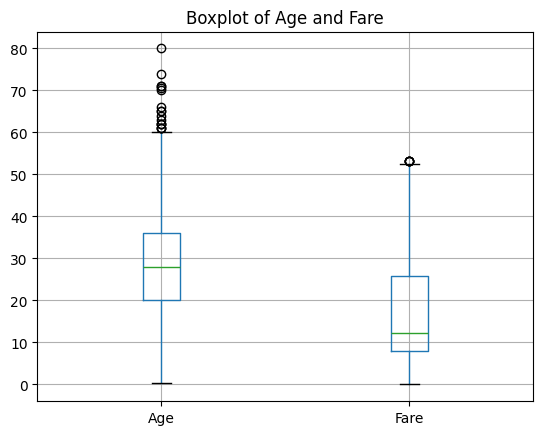

In [49]:
import matplotlib.pyplot as plt


titanic_data_boxplot = titanic_data.boxplot(column = ['Age', 'Fare'])

plt.title('Boxplot of Age and Fare')
plt.show()



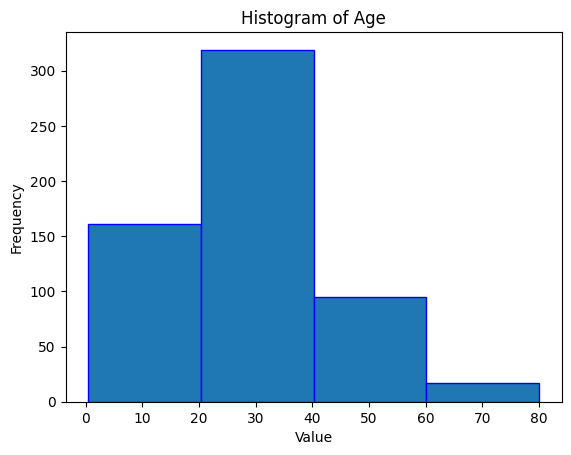

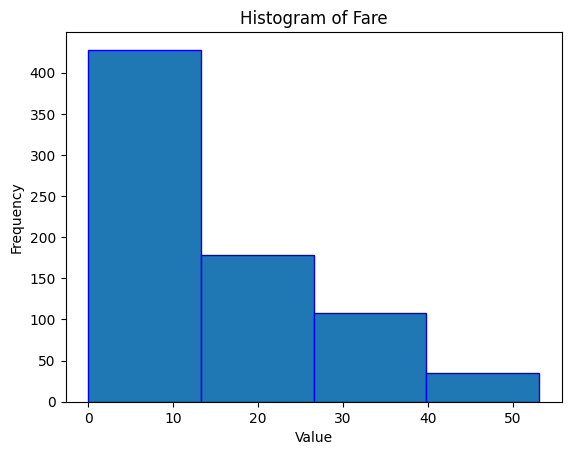

In [48]:
plt.hist(titanic_data['Age'], bins = 4, edgecolor='blue')

plt.title('Histogram of Age')
plt.xlabel('Value')
plt.ylabel('Frequency')
plt.show()

plt.hist(titanic_data['Fare'], bins = 4, edgecolor='blue')

plt.title('Histogram of Fare')
plt.xlabel('Value')
plt.ylabel('Frequency')
plt.show()

In [62]:
import numpy as np

# 1. Calculate Q1 (25th percentile) and Q3 (75th percentile)
q1, q3 = np.percentile(titanic_data['Fare'], [25, 75])

# 2. Calculate the Interquartile Range
IQR = q3 - q1

# 3. Determine the lower and upper bounds (Fences)
lower_fence = q1 - (1.5 * IQR)
upper_fence = q3 + (1.5 * IQR)

# 4. Extract the outliers
flagged_outliers = [x for x in titanic_data['Fare'] if x < lower_fence or x > upper_fence]
cleaned_data = [x for x in titanic_data['Fare'] if lower_fence <= x <= upper_fence]

print(f"Calculated IQR: {IQR}")
print(f"Lower Fence: {lower_fence:.2f} | Upper Fence: {upper_fence:.2f}")
print(f"Detected Outliers: {flagged_outliers}")

Calculated IQR: 17.944824999999998
Lower Fence: -19.02 | Upper Fence: 52.76
Detected Outliers: [53.1, 53.1, 53.1, 53.1, 53.1]


In [66]:
titanic_data['Age'].isna().any()
titanic_data['Age']= titanic_data['Age'].fillna(0)


# 1. Calculate Q1 (25th percentile) and Q3 (75th percentile)
q1, q3 = np.percentile(titanic_data['Age'], [25, 75])

# 2. Calculate the Interquartile Range
IQR = q3 - q1

# 3. Determine the lower and upper bounds (Fences)
lower_fence = q1 - (1.5 * IQR)
upper_fence = q3 + (1.5 * IQR)

# 4. Extract the outliers
flagged_outliers = [x for x in titanic_data['Age'] if x < lower_fence or x > upper_fence]
cleaned_data = [x for x in titanic_data['Age'] if lower_fence <= x <= upper_fence]

print(f"Calculated IQR: {IQR}")
print(f"Lower Fence: {lower_fence:.2f} | Upper Fence: {upper_fence:.2f}")
print(f"Detected Outliers: {flagged_outliers}")

Calculated IQR: 30.0
Lower Fence: -41.00 | Upper Fence: 79.00
Detected Outliers: [80.0]


In [67]:
upper_limit = titanic_data['Age'].quantile(0.98)

# Keep only the rows below the threshold
titanic_data_filtered = titanic_data[titanic_data['Age'] <= upper_limit]



🌟 Exercise 5: Data Standardization and Normalization
Goal: Scale numerical features to prepare for modeling.

Use StandardScaler (mean = 0, std = 1) for normally distributed features.
Use MinMaxScaler (range [0, 1]) for features that are skewed or bounded.
📌 Important: Perform this step after outlier treatment to avoid distortion caused by extreme values.



In [72]:
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler

ssscaler = StandardScaler()

# 2. Fit and transform using double brackets [df[['column']]] to keep it 2D
titanic_data_filtered['Fare'] = ssscaler.fit_transform(titanic_data_filtered[['Fare']])

print(titanic_data_filtered)

minmax_scale=MinMaxScaler()
titanic_data_filtered['Fare'] = minmax_scale.fit_transform(titanic_data_filtered[['Fare']])

print(titanic_data_filtered)


     PassengerId  Survived  Pclass  \
0              1         0       3   
2              3         1       3   
3              4         1       1   
4              5         0       3   
5              6         0       3   
..           ...       ...     ...   
886          887         0       2   
887          888         1       1   
888          889         0       3   
889          890         1       1   
890          891         0       3   

                                             Name     Sex   Age  SibSp  Parch  \
0                         Braund, Mr. Owen Harris    male  22.0      1      0   
2                          Heikkinen, Miss. Laina  female  26.0      0      0   
3    Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1      0   
4                        Allen, Mr. William Henry    male  35.0      0      0   
5                                Moran, Mr. James    male   0.0      0      0   
..                                            ...     ...

/tmp/ipykernel_1164/2776211991.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  titanic_data_filtered['Fare'] = ssscaler.fit_transform(titanic_data_filtered[['Fare']])
/tmp/ipykernel_1164/2776211991.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  titanic_data_filtered['Fare'] = minmax_scale.fit_transform(titanic_data_filtered[['Fare']])





🌟 Exercise 6: Feature Encoding
Goal: Finalize categorical variable encoding.

1. Identify remaining categorical columns (e.g. Sex, Embarked, Title).
2. Apply:

One-Hot Encoding for nominal variables.
Label Encoding if any ordinal variables remain.
3. Merge encoded columns back into the main dataset.

📌 Reminder: Encoding comes after handling missing values and outliers, but before scaling (if applicable).


In [79]:
#finalize categorical variable encoding

#one-hot encoding for nominal variables (sex, title, embarked)
titanic_data['Embarked'] = titanic_data['Embarked'].fillna(titanic_data['Embarked'].mode()[0])

updated_titanic_data = pd.get_dummies(titanic_data, columns=['Embarked'], prefix='Embarked', dtype=int)
updated_titanic_data2 = pd.get_dummies(updated_titanic_data, columns=['Title'], prefix='Title', dtype=int)
updated_titanic_data3 = pd.get_dummies(updated_titanic_data2, columns=['Sex'], prefix='Sex', dtype=int)


#merge encoded columns back into dataset

# print(updated_titanic_data3.describe())

       PassengerId    Survived      Pclass         Age       SibSp  \
count   750.000000  750.000000  750.000000  750.000000  750.000000   
mean    445.746667    0.325333    2.508000   22.656333    0.438667   
std     260.420103    0.468812    0.711766   17.306957    0.910317   
min       1.000000    0.000000    1.000000    0.000000    0.000000   
25%     214.250000    0.000000    2.000000    4.000000    0.000000   
50%     449.500000    0.000000    3.000000   23.750000    0.000000   
75%     670.750000    1.000000    3.000000   34.000000    1.000000   
max     891.000000    1.000000    3.000000   80.000000    5.000000   

            Parch        Fare  Family_Size    Is_Alone  Title_Encoded  ...  \
count  750.000000  750.000000   750.000000  750.000000     750.000000  ...   
mean     0.337333   16.477733     1.776000    0.660000       1.670667  ...   
std      0.790172   11.581224     1.433142    0.474025       1.020259  ...   
min      0.000000    0.000000     1.000000    0.000000   






🌟 Exercise 7: Data Transformation for Age Feature
Goal: Create and encode age groups.

Use pd.cut() to create bins for life stages (e.g. child, teen, adult, senior).
Apply one-hot encoding using pd.get_dummies().
📌 Example: You might define bins like [0, 12, 18, 60, 100] and label them accordingly.


In [81]:
# 1. Define your bin edges and their corresponding labels
# Bins: 0-12 (Child), 12-18 (Teen), 18-60 (Adult), 60-100 (Senior)
age_bins = [0, 12, 18, 60, 100]
age_labels = ['Child', 'Teen', 'Adult', 'Senior']

# 2. Use pd.cut to create the new categorical 'Age_Group' feature
# (Make sure to apply this to your latest DataFrame, 'updated_titanic_data3')
updated_titanic_data3['Age_Group'] = pd.cut(updated_titanic_data3['Age'], bins=age_bins, labels=age_labels)

# 3. Apply one-hot encoding to the new 'Age_Group' column
updated_titanic_data3 = pd.get_dummies(
    updated_titanic_data3,
    columns=['Age_Group'],
    prefix='Age',
    dtype=int)

print(updated_titanic_data3.info())

<class 'pandas.core.frame.DataFrame'>
Index: 750 entries, 0 to 890
Data columns (total 65 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   PassengerId     750 non-null    int64  
 1   Survived        750 non-null    int64  
 2   Pclass          750 non-null    int64  
 3   Name            750 non-null    object 
 4   Age             750 non-null    float64
 5   SibSp           750 non-null    int64  
 6   Parch           750 non-null    int64  
 7   Ticket          750 non-null    object 
 8   Fare            750 non-null    float64
 9   Family_Size     750 non-null    int64  
 10  Is_Alone        750 non-null    int64  
 11  Title_Encoded   750 non-null    int64  
 12  Title_Col       750 non-null    int64  
 13  Title_Don       750 non-null    int64  
 14  Title_Dr        750 non-null    int64  
 15  Title_Jonkheer  750 non-null    int64  
 16  Title_Lady      750 non-null    int64  
 17  Title_Major     750 non-null    int64  
